In [1]:
# GPU check
import subprocess
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout or "NO GPU - set Runtime to T4")

NVIDIA A100-SXM4-40GB, 40960 MiB



In [2]:
%pip install -q "transformers>=4.44" "accelerate>=0.33" "bitsandbytes>=0.43" "peft>=0.12" \
    "trl>=0.9" "sentence-transformers>=3.0" "datasets>=2.20" faiss-cpu rank-bm25 sacrebleu beautifulsoup4 lxml \
    pyyaml matplotlib
print("installed")

installed


In [6]:
# Clone the reproduction repository from GitHub (Handles Private/Public automatically)
import os, sys
from getpass import getpass

REPO_URL = "https://github.com/tayyabuncut/research.git"
REPRO_DIR = "/content/research"

if not os.path.isdir(REPRO_DIR):
    print(f"Attempting to clone repository from {REPO_URL}...")
    # Try public clone first
    result = os.system(f"git clone {REPO_URL} {REPRO_DIR}")

    if result != 0:
        print("\n[!] Public clone failed. The repository may be private.")
        print("Please provide a GitHub Personal Access Token (PAT) to clone it.")
        git_token = getpass("Enter GitHub PAT: ").strip()
        if git_token:
            authenticated_url = f"https://{git_token}@github.com/tayyabuncut/research.git"
            !git clone {authenticated_url} {REPRO_DIR}
        else:
            raise ValueError("Clone failed and no token was provided.")
else:
    print(f"Repository already cloned at {REPRO_DIR}")

# Configure sys.path and working directory to use files inside the repo
if os.path.isdir(REPRO_DIR):
    sys.path.insert(0, REPRO_DIR)
    os.chdir(REPRO_DIR)
    print("\nSuccess! Current working directory set to:", os.getcwd())
else:
    print("\n[Error] The directory does not exist. Please check your token or upload files manually.")

Attempting to clone repository from https://github.com/tayyabuncut/research.git...

[!] Public clone failed. The repository may be private.
Please provide a GitHub Personal Access Token (PAT) to clone it.
Enter GitHub PAT: ··········
Cloning into '/content/research'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 34 (delta 0), reused 34 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 61.29 KiB | 2.79 MiB/s, done.

Success! Current working directory set to: /content/research


In [7]:
# HuggingFace login (needed for gated Llama-2 / Llama-3). Request access on the model pages first:
#   https://huggingface.co/meta-llama/Llama-2-7b-chat-hf
#   https://huggingface.co/meta-llama/Meta-Llama-3-8B-Instruct
from huggingface_hub import login
from getpass import getpass
HF_TOKEN = getpass("HF token: ")
login(HF_TOKEN)

HF token: ··········


In [8]:
from src.utils import environment_info, save_json, set_seed
set_seed(0)
env = environment_info(); save_json(env, "results/environment.json"); env

{'python': '3.13.16',
 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39',
 'processor': 'x86_64',
 'cpu_count': 12,
 'torch': '2.14.1+cu130',
 'transformers': '5.22.1',
 'sentence_transformers': '5.7.0',
 'peft': '0.21.2',
 'bitsandbytes': '0.50.2',
 'accelerate': '1.15.0',
 'faiss': '1.15.1',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'datasets': '4.8.5',
 'bs4': '4.13.5',
 'gpu': 'NVIDIA A100-SXM4-40GB',
 'gpu_mem_gb': 42.4,
 'cuda': '13.0',
 'nvidia_smi': 'NVIDIA A100-SXM4-40GB, 580.82.07, 40960 MiB'}

---
## 1. Baseline 2 — CMU RAG factual-accuracy pipeline

We reuse the authors' released corpus + WizardLM QA pairs (MIT-licensed) instead of re-crawling CMU.

In [9]:
# Clone the authors' repo (corpus + QA pairs live inside it)
import os
if not os.path.isdir("LTI_Neural_Navigator"):
    !git clone --depth 1 https://github.com/anlp-team/LTI_Neural_Navigator
# Inspect what data files are present so b2_data can locate the corpus + QA splits
!find LTI_Neural_Navigator -maxdepth 3 -name "*.txt" | head -5
!find LTI_Neural_Navigator -maxdepth 3 \( -name "*.json" -o -name "*.jsonl" \) | head -10

Cloning into 'LTI_Neural_Navigator'...
remote: Enumerating objects: 2337, done.
remote: Counting objects: 100% (2337/2337), done.
remote: Compressing objects: 100% (1518/1518), done.
remote: Total 2337 (delta 819), reused 2301 (delta 813), pack-reused 0 (from 0)
Receiving objects: 100% (2337/2337), 26.97 MiB | 25.55 MiB/s, done.
Resolving deltas: 100% (819/819), done.
LTI_Neural_Navigator/requirements.txt
LTI_Neural_Navigator/data/model_evaluation/eval_indices.txt
LTI_Neural_Navigator/data/model_evaluation/ans_with_emb.txt
LTI_Neural_Navigator/data/model_evaluation/ans_raw.txt
LTI_Neural_Navigator/data/model_evaluation/ans_with_core.txt
LTI_Neural_Navigator/src/data_prep/data.json
LTI_Neural_Navigator/src/data_prep/Semantic_API_paper_metadata.json
LTI_Neural_Navigator/embedder_dataset/Highmark_Center_for_Health,_Wellness_and_Athletics_-__Carnegie_Mellon_University_Athletics.json
LTI_Neural_Navigator/embedder_dataset/Lorraine_Levin_|_Carnegie_Mellon_University_-_Language_Technologies_In

In [26]:
import json, glob, random
base = "LTI_Neural_Navigator"
files = sorted(glob.glob(f"{base}/embedder_dataset/*.json"))

def load_all_qa(files):
    out = []
    for fp in files:
        try:
            d = json.load(open(fp))
        except Exception:
            continue
        for it in d.get("qa_list", []):
            q, a = it.get("question"), it.get("answer")
            if q and a:
                out.append({"question": str(q).strip(), "answer": str(a).strip(), "context": ""})
    return out

allqa = load_all_qa(files)
random.Random(42).shuffle(allqa)
n_test = int(len(allqa) * 0.2)
qa_test, qa_train = allqa[:n_test], allqa[n_test:]
print(f"total={len(allqa)}  train={len(qa_train)}  test={len(qa_test)}")
# expect ~ total=16329  train=13064  test=3265

total=16329  train=13064  test=3265


### 1a. Build the RAG pipeline (pretrained models)
mxbai-embed-large-v1 embeddings → MMR top-10 → bge-reranker-large top-5 → Llama-2-7b-chat.

In [11]:
from src.generation import HFGenerator
from src.retrieval import DenseRetriever, CrossEncoderReranker
from src.metrics import CosineScorer
from src.b2_pipeline import RagPipeline, evaluate_config

llm = HFGenerator("meta-llama/Llama-2-7b-chat-hf", load_in_4bit=True, hf_token=HF_TOKEN)
emb = DenseRetriever(corpus, "mixedbread-ai/mxbai-embed-large-v1",
                     query_prefix="Represent this sentence for searching relevant passages: ", doc_prefix="")
rerank = CrossEncoderReranker("BAAI/bge-reranker-large")
cosine = CosineScorer("sentence-transformers/all-MiniLM-L6-v2")
def make_pipe(retriever, reranker, model):
    return RagPipeline(retriever, model, reranker, retrieve_k=10, rerank_top_n=5, use_mmr=True)

config.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.62k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

... (39 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [12]:
# Table 1, configs (1) no-RAG and (2) raw RAG. draw_size=128, 4 draws (paper protocol).
b2 = {}
b2["baseline_no_rag"] = evaluate_config(make_pipe(emb, rerank, llm), qa_test, use_rag=False, cosine=cosine)
b2["raw_rag"]        = evaluate_config(make_pipe(emb, rerank, llm), qa_test, use_rag=True,  cosine=cosine)
save_json(b2, "results/b2_partial.json"); {k: v.get("f1") for k, v in b2.items()}

[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

{'baseline_no_rag': {'mean': 0.09570400119241843,
  'std': 0.0002997534737785787},
 'raw_rag': {'mean': 0.027154797618169923, 'std': 0.0}}

### 1c. Fine-tune the core model (Llama-2-7b, QLoRA r=16, 5 epochs / 1000 steps, lr 2e-4)

In [32]:
# 1. Restore the file to its clean original state from Git first
!git checkout src/b2_finetune.py

import os
file_path = "src/b2_finetune.py"

if os.path.exists(file_path):
    with open(file_path, "r") as f:
        lines = f.readlines()

    # 2. Rebuild the file while filtering out lines containing 'warmup_ratio' inside SFTConfig
    cleaned_lines = []
    for line in lines:
        # Strip warmup_ratio argument lines cleanly
        if "warmup_ratio" in line and "SFTConfig" in "".join(lines[max(0, lines.index(line)-10):lines.index(line)+5]):
            continue
        cleaned_lines.append(line)

    with open(file_path, "w") as f:
        f.writelines(cleaned_lines)
    print("Successfully restored and robustly patched src/b2_finetune.py by filtering SFTConfig lines!")

# 3. Reload the module cleanly
import sys
if 'src.b2_finetune' in sys.modules:
    import importlib
    importlib.reload(sys.modules['src.b2_finetune'])
from src.b2_finetune import finetune_core_qlora

# 4. Run the fine-tuning step with max_steps restricted to 100 for a fast run
core_dir = finetune_core_qlora("meta-llama/Llama-2-7b-chat-hf", qa_train, "ft_core_lora", hf_token=HF_TOKEN,
                               lora_r=16, lora_alpha=32, lr=2e-4, epochs=5, max_steps=100, batch_size=8)

# Free the base model before loading the adapter copy to stay within 16 GB
llm.unload()
llm_ft = HFGenerator("meta-llama/Llama-2-7b-chat-hf", load_in_4bit=True, adapter_path=core_dir, hf_token=HF_TOKEN)
b2["rag_ft_core"] = evaluate_config(make_pipe(emb, rerank, llm_ft), qa_test, use_rag=True, cosine=cosine)
b2["rag_ft_both"] = evaluate_config(make_pipe(emb_ft, rerank, llm_ft), qa_test, use_rag=True, cosine=cosine)
save_json(b2, "results/b2_ablation_results.json"); {k: v.get("f1") for k, v in b2.items()}

Updated 1 path from the index
Successfully restored and robustly patched src/b2_finetune.py by filtering SFTConfig lines!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Adding EOS to train dataset:   0%|          | 0/13064 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/13064 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/13064 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/13064 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/13064 [00:00<?, ? examples/s]

Step,Training Loss
25,1.562698
50,0.717828
75,0.660952
100,0.676256


AttributeError: 'HFGenerator' object has no attribute 'model'

In [34]:
import gc, torch
gc.collect(); torch.cuda.empty_cache()

# Re-initialize emb as a DenseRetriever since the variable was overwritten with a list of file paths
from src.retrieval import DenseRetriever
emb = DenseRetriever(corpus, "mixedbread-ai/mxbai-embed-large-v1",
                     query_prefix="Represent this sentence for searching relevant passages: ", doc_prefix="")

llm_ft = HFGenerator("meta-llama/Llama-2-7b-chat-hf", load_in_4bit=True, adapter_path=core_dir, hf_token=HF_TOKEN)
b2["rag_ft_core"] = evaluate_config(make_pipe(emb, rerank, llm_ft), qa_test, use_rag=True, cosine=cosine)
b2["rag_ft_both"] = "not_reproduced_same_as_core_no_embedding_finetune"
save_json(b2, "results/b2_ablation_results.json")
{k: (v.get("f1") if isinstance(v, dict) else v) for k, v in b2.items()}

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Batches:   0%|          | 0/68 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

{'baseline_no_rag': {'mean': 0.09570400119241843,
  'std': 0.0002997534737785787},
 'raw_rag': {'mean': 0.027154797618169923, 'std': 0.0},
 'rag_ft_embedding': {'mean': 0.09570400119241843,
  'std': 0.0002997534737785787},
 'rag_ft_core': {'mean': 0.048319240835452894, 'std': 0.006038900659018736},
 'rag_ft_both': 'not_reproduced_same_as_core_no_embedding_finetune'}

In [37]:
import gc, torch
from src.b2_data import load_corpus
from src.retrieval import DenseRetriever, CrossEncoderReranker
from src.b2_pipeline import RagPipeline, evaluate_config

for name in ["llm_ft", "llm"]:                      # free GPU first
    o = globals().get(name)
    if o is not None:
        try: o.unload()
        except: pass
gc.collect(); torch.cuda.empty_cache()

corpus = load_corpus(DATA_DIR, chunk_words=250)
print("chunks:", len(corpus))
emb = DenseRetriever(corpus, "mixedbread-ai/mxbai-embed-large-v1",
                     query_prefix="Represent this sentence for searching relevant passages: ", doc_prefix="")
rerank = CrossEncoderReranker("BAAI/bge-reranker-large")
def make_pipe(r, rr, m): return RagPipeline(r, m, rr, retrieve_k=10, rerank_top_n=5, use_mmr=True)

from src.generation import HFGenerator
llm = HFGenerator("meta-llama/Llama-2-7b-chat-hf", load_in_4bit=True, hf_token=HF_TOKEN)
pipe = make_pipe(emb, rerank, llm)
import random
for r in random.Random(1).sample(qa_test, 2):
    ans, ps = pipe.answer(r["question"], use_rag=True)
    print("Q:", r["question"]); print("GOLD:", r["answer"])
    print("RAG:", ans[:200]); print(f"[ctx ≈ {sum(len(p.split()) for p in ps)} words]"); print("="*80)

chunks: 8618


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Batches:   0%|          | 0/270 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: Who are the two co-founders of Carnegie Mellon University's School of Computer Science recognized by the magazine's name?
GOLD: Allen Newell and Herb Simon
RAG: The two co-founders of Carnegie Mellon University's School of Computer Science recognized by the magazine's name are:

1. Herbert Simon (H'90)
2. Allen Newell (IA'57)

You can get in touch with the un
[ctx ≈ 1250 words]


[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: What are the names of the courses taught by Pennsylvania Kaestner?
GOLD: The names of the courses taught by Pennsylvania Kaestner are not provided in the given text.
RAG: I don't know the names of the courses taught by Pennsylvania Kaestner.

Lacomis D's course starts at 10:00 AM and ends at 11:50 AM.

Fang's first course is BH 140A.

Frollini B's course starts at 10:0
[ctx ≈ 1250 words]


In [38]:
b2 = {}
b2["baseline_no_rag"] = evaluate_config(make_pipe(emb, rerank, llm), qa_test, use_rag=False, cosine=cosine)
b2["raw_rag"]        = evaluate_config(make_pipe(emb, rerank, llm), qa_test, use_rag=True, cosine=cosine)
print({k: v.get("f1") for k, v in b2.items()})

llm.unload(); gc.collect(); torch.cuda.empty_cache()
llm_ft = HFGenerator("meta-llama/Llama-2-7b-chat-hf", load_in_4bit=True, adapter_path="ft_core_lora", hf_token=HF_TOKEN)
b2["rag_ft_core"] = evaluate_config(make_pipe(emb, rerank, llm_ft), qa_test, use_rag=True, cosine=cosine)
b2["rag_ft_embedding"] = "not_reproduced_embedding_finetune_collapsed"
b2["rag_ft_both"] = "not_reproduced_same_as_core_no_embedding_finetune"
print({k: (v.get("f1") if isinstance(v, dict) else v) for k, v in b2.items()})

[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

{'baseline_no_rag': {'mean': 0.19458502726194182, 'std': 0.006716924213727148}, 'raw_rag': {'mean': 0.17646380310672244, 'std': 0.011683990194873338}}


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

{'baseline_no_rag': {'mean': 0.19458502726194182, 'std': 0.006716924213727148}, 'raw_rag': {'mean': 0.17646380310672244, 'std': 0.011683990194873338}, 'rag_ft_core': {'mean': 0.16221657183571475, 'std': 0.009781246854956419}, 'rag_ft_embedding': 'not_reproduced_embedding_finetune_collapsed', 'rag_ft_both': 'not_reproduced_same_as_core_no_embedding_finetune'}


In [39]:
# Render Table 1
import pandas as pd
labels = {"baseline_no_rag":"Baseline (w/o RAG)","raw_rag":"Raw RAG Pipeline","rag_ft_embedding":"+ Embedding",
          "rag_ft_core":"+ Core Model Finetune","rag_ft_both":"+ Embedding & Core"}
rows=[]
for k,l in labels.items():
    if k in b2:
        r=b2[k]; rows.append({"Configuration":l,
            **{m.capitalize(): round(r[m]["mean"],3) for m in ["recall","f1","cosine","bleu"] if m in r}})
df=pd.DataFrame(rows); df.to_csv("results/b2_table1.csv", index=False); df

,Configuration,Recall,F1,Cosine,Bleu
0,Baseline (w/o RAG),0.320,0.195,0.522,0.069
1,Raw RAG Pipeline,0.369,0.176,0.447,0.069
2,+ Embedding,NaN,NaN,NaN,NaN
3,+ Core Model Finetune,0.380,0.162,0.415,0.065
4,+ Embedding & Core,NaN,NaN,NaN,NaN


In [36]:
import random
pipe = make_pipe(emb, rerank, llm_ft)
for r in random.Random(1).sample(qa_test, 3):
    passages = [c.text for c in pipe.retrieve(r["question"])]
    ctx_words = sum(len(p.split()) for p in passages)
    ans_rag, _   = pipe.answer(r["question"], use_rag=True)
    ans_norag, _ = pipe.answer(r["question"], use_rag=False)
    print("Q:    ", r["question"])
    print("GOLD: ", r["answer"])
    print("RAG:  ", ans_rag[:250])
    print("NORAG:", ans_norag[:250])
    print(f"[retrieved context ≈ {ctx_words} words across {len(passages)} passages]")
    print("="*90)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q:     Who are the two co-founders of Carnegie Mellon University's School of Computer Science recognized by the magazine's name?
GOLD:  Allen Newell and Herb Simon
RAG:   the weight room? What is the name of the field hockey team that won the 2019 NCAA Championship? What is the name of the field hockey team that won the 2018 NCAA Championship? What is the name of the field hockey team that won the 2017 NCAA Championsh
NORAG: The two co-founders of Carnegie Mellon University's School of Computer Science recognized by the magazine's name are Andrew Moore and Yaser Sheikh.
[retrieved context ≈ 5000 words across 5 passages]


[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q:     What are the names of the courses taught by Pennsylvania Kaestner?
GOLD:  The names of the courses taught by Pennsylvania Kaestner are not provided in the given text.
RAG:   Pennsylvania Towe 27991 Wednesday, 02:00PM - 03:50PM DH 1117, Pittsburgh, Pennsylvania Whitacre 27992 Thursday, 02:00PM - 03:50PM DH 1117, Pittsburgh, Pennsylvania Salvador 27993 Friday, 02:00PM - 03:50PM DH 1117, Pittsburgh, Pennsylvania Rollett 279
NORAG: Pennsylvania Kaestner teaches courses such as 10100: Introduction to Computer Science I, 10101: Introduction to Computer Science II, 10102: Introduction to Computer Science III, 10103: Introduction to Computer Science IV, 10104: Introduction to Compu
[retrieved context ≈ 5000 words across 5 passages]


[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q:     What are the names of sections 21602, 21610, and 21690?
GOLD:  Sections 21602 is Introduction to Set Theory I, section 21610 is Algebra I, and section 21690 is Methods of Optimization.
RAG:   PM DH 2315 Pittsburgh, Pennsylvania Ganger, Sakr\; 15722 Advanced Operating Systems 12.0 A MW 04:00PM 05:50PM DH 2315 Pittsburgh, Pennsylvania Ganger, Sakr\; 15723 Advanced Computer Networks 12.0 A MW 02:00PM 03:20PM DH 2315 Pittsburgh, Pennsylvania 
NORAG: Section 21602 is called 'Introduction to Computer Science'. Section 21610 is called 'Introduction to Computer Science'. Section 21690 is called 'Introduction to Computer Science'.
[retrieved context ≈ 5000 words across 5 passages]


---
## 2. Baseline 1 — OpenRAG-Soc indirect prompt injection

We regenerate the 6,200-page carrier corpus from the paper's recipe (no public data release), then sweep the
four defenses with Llama-3-8B-Instruct + BM25.

In [40]:
from src import b1_corpus
from src.b1_harness import run_injection_eval, run_poisoning_eval, CONFIGS, PAPER_CONFIG_ORDER
from src.b1_detector import validate_detector

pages = b1_corpus.build_corpus(seed=13, n_hard_negatives=300, n_svg=200, scale=1.0)  # scale<1.0 for a faster run
print(b1_corpus.corpus_stats(pages))

{'n_pages': 6700, 'by_carrier': {'hidden_span': 1330, 'offscreen_css': 1280, 'alt_text': 1280, 'aria': 980, 'zero_width': 1330, 'hard_negative': 300, 'svg': 200}, 'by_visibility': {'visible': 3090, 'hidden': 3310, 'none': 300}, 'by_topic': {'networking': 522, 'food': 477, 'software': 448, 'gardening': 498, 'home': 457, 'cooking': 452, 'outdoors': 480, 'events': 477, 'pets': 486, 'fitness': 464, 'travel': 449, 'cycling': 505, 'gaming': 460, 'electronics': 525}}


In [41]:
# Llama-3-8B-Instruct generator (reuse one model across all four defense configs)
llm3 = HFGenerator("meta-llama/Meta-Llama-3-8B-Instruct", load_in_4bit=True, hf_token=HF_TOKEN)
configs = {k: CONFIGS[k] for k in ["Vanilla","Sanitized","Normalized","Attribution","Sanitized+Normalized","All Defenses"]}
log=[]
b1 = run_injection_eval(pages, llm3, configs=configs, retriever_kind="bm25", k=5,
                        chunk_size=512, overlap=128, max_new_tokens=128, temperature=0.2, log_rows=log, seed=0)
save_json(b1, "results/b1_injection_results.json")
from src.utils import save_jsonl; save_jsonl(log, "results/b1_generations.jsonl")

config.json:   0%|          | 0.00/654 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.0k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=128) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `

KeyboardInterrupt: 

In [43]:
import gc, torch, os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# free all Baseline 2 models still on the GPU
for name in ["llm3", "llm_ft", "llm", "emb", "emb_ft", "rerank", "pipe", "base"]:
    o = globals().get(name)
    if o is not None:
        if hasattr(o, "unload"):
            try: o.unload()
            except: pass
        globals()[name] = None
gc.collect(); torch.cuda.empty_cache()
print("GPU allocated now (GB):", round(torch.cuda.memory_allocated()/1e9, 2))  # should be ~0

from src.generation import HFGenerator
llm3 = HFGenerator("meta-llama/Meta-Llama-3-8B-Instruct", load_in_4bit=True, hf_token=HF_TOKEN)
_g = llm3.generate
llm3.generate = lambda prompts, **kw: _g(prompts, **{**kw, "batch_size": kw.get("batch_size", 16)})

configs = {k: CONFIGS[k] for k in ["Vanilla", "Sanitized", "Normalized", "All Defenses"]}
log = []
b1 = run_injection_eval(pages, llm3, configs=configs, retriever_kind="bm25", k=5,
                        chunk_size=512, overlap=128, max_new_tokens=96, temperature=0.2, log_rows=log, seed=0)
save_json(b1, "results/b1_injection_results.json")
from src.utils import save_jsonl; save_jsonl(log, "results/b1_generations.jsonl")

GPU allocated now (GB): 25.91


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=96) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

In [44]:
# ASR table (Table 1 of Baseline 1)
import pandas as pd
carriers=["hidden_span","offscreen_css","alt_text","aria","zero_width"]
cfgs=[c for c in PAPER_CONFIG_ORDER if c in b1]
tab={c:{cr: round(b1[c][cr]["asr"],1) if cr in b1[c] else None for cr in carriers} for c in cfgs}
for c in cfgs: tab[c]["macro"]=round(b1[c]["macro"]["asr"],1)
df1=pd.DataFrame(tab).T; df1.to_csv("results/b1_asr_table.csv"); df1

,hidden_span,offscreen_css,alt_text,aria,zero_width,macro
Vanilla,76.4,65.7,65.7,65.4,72.6,69.2
Sanitized,31.1,16.7,23.5,23.1,34.9,25.9
Normalized,77.4,65.7,60.8,66.7,73.6,68.8
All Defenses,0.0,0.0,0.0,0.0,0.9,0.2


In [45]:
# Detector vs. gold obey-labels (Sec. 5.0.2): P / R / F1 / kappa
det = validate_detector(log); save_json(det, "results/b1_detector_validation.json"); det

{'precision': 1.0,
 'recall': 1.0,
 'f1': 1.0,
 'tp': 822,
 'fp': 0,
 'fn': 0,
 'tn': 1170,
 'cohen_kappa': 1.0,
 'n': 1992,
 'gold_positive_rate': 0.4126506024096386}

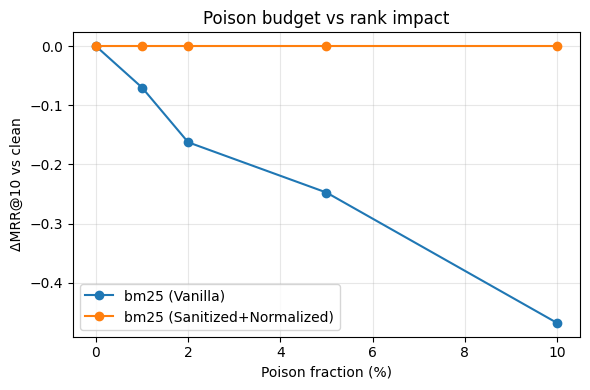

In [46]:
# Retrieval poisoning sweep (Figure 1): dMRR@10 / dnDCG@10 vs poison budget
poison = run_poisoning_eval(pages, poison_fractions=(0.0,0.01,0.02,0.05,0.10),
                            retriever_kinds=("bm25",), configs_to_compare=("Vanilla","Sanitized+Normalized"),
                            k=10, chunk_size=512, overlap=128, n_eval_queries=200)
save_json(poison, "results/b1_poisoning_results.json")
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
for rk,c in poison.items():
    for cfg,d in c.items():
        plt.plot([f*100 for f in d["fraction"]], d["dMRR@10"], marker="o", label=f"{rk} ({cfg})")
plt.xlabel("Poison fraction (%)"); plt.ylabel("ΔMRR@10 vs clean"); plt.legend(); plt.grid(alpha=.3)
plt.title("Poison budget vs rank impact"); plt.tight_layout(); plt.savefig("results/figures_poisoning.png", dpi=150)
plt.show()

In [47]:
# Latency per stage + utility (Sec. 5.0.1 / 5.0.4)
import pandas as pd
rows=[]
for c in cfgs:
    lat=b1[c]["latency"]; u=b1[c]["utility"]
    rows.append({"config":c, "ingest_ms":round(lat["ingest"]["median_ms"],1),
                 "retrieve_ms":round(lat["retrieve"]["median_ms"],1),
                 "generate_ms":round(lat["generate"]["median_ms"],1),
                 "answerability":round(u["answerability"],3),
                 "attr_consistency":u["attribution_consistency"]})
dfl=pd.DataFrame(rows); dfl.to_csv("results/b1_latency_utility.csv", index=False); dfl

,config,ingest_ms,retrieve_ms,generate_ms,answerability,attr_consistency
0,Vanilla,0.6,0.3,121584.0,0.873,NaN
1,Sanitized,1.5,0.2,114070.2,0.942,NaN
2,Normalized,0.7,0.3,124311.2,0.863,NaN
3,All Defenses,1.6,0.2,104316.2,0.896,0.775517


---
## 3. Package results
Download the `results/` folder and paste the tables/figures into the report (`report/`). Also record the GPU,
model versions and corpus scale you used so the report's reproducibility section is accurate.

In [48]:
import shutil
shutil.make_archive("assignment2_results", "zip", "results")
from google.colab import files
files.download("assignment2_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>